# Figure 3 condition comparisons — supplementary

Independent supplementary notebook. The original multiphase plotting
definitions below are copied verbatim from `vizpub/fig3.ipynb` (helpers and
restructured multiphase stack). No main notebook is executed or modified.

Three comparisons: Picture Naming Repeat sound/image; Lexical Delay sound
Decision/Repeat; Picture Naming sound Repeat/Passive. Each comparison is
saved and shown as two SVGs, not embedded into one file: the three-phase
HGA stack, and the brain maps. The HGA stack has three phases and three
component rows, each with electrode mean ± SEM above paired, baseline-masked
heatmaps. The brain maps have one row per condition and left/right insula.
The mapped phase is **Stimulus** for Sound–Image and Repeat–Passive, and
**Delay** for Decision–Repeat. Its HGA column is labeled without a border;
the brain-map header states the exact same displayed window. Colored sites
are responsive to baseline in that window, not between-condition differences.

Frozen current NMF labels and original colors, display limits, summary,
ordering, P95 scales and mask-false blanking are retained. Native restoration
QC remains in force. Passive Response reuses the original stored nominal
alignment, restricted to the current good task electrode set. It has no
actual vocal onset. No new inferential test or time alignment is introduced.


In [8]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg')
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_hex, to_rgb
from matplotlib.lines import Line2D
from matplotlib import font_manager
from IPython.display import SVG, display
ROOT = Path('/cwork/ns458/insula-paper')
sys.path.insert(0, str(ROOT))
from src.nmf.waveform_analysis import FUNCTION_COLORS, CLUSTER_LABELS
from src.paths import save_svg
from src.supplementary.context_comparisons import load_context_data, condition_phase_maps, draw_brain_maps, fit_hga_canvas, highlight_mapped_phase, CONTRASTS, PHASES, DISPLAY_WINDOWS
OUT = ROOT / 'results/supplementary/context_comparisons'
IMG = ROOT / 'img/supplementary/context_comparisons'
IMG.mkdir(parents=True, exist_ok=True)
cm = 1 / 2.54
fontsize = 7
for font in Path(sys.prefix, 'fonts').glob('arial*.ttf'):
    font_manager.fontManager.addfont(str(font))
plt.rcParams.update({'svg.fonttype':'none', 'font.family':'sans-serif', 'font.sans-serif':['Arial'], 'font.size':7})
rfig3_clusters = ['sensory', 'sustain', 'motor']
rfig3_cluster_labels = dict(sensory='sensory', sustain='sustained', motor='motor')
RFIG3_STACK_BASE_WIDTH_CM = 2.5
RFIG3_TRACE_HEIGHT_CM = 1.5
RFIG3_CM_PER_RASTER_ROW = 0.02
RFIG3_PHASE_ORDER = ('stimulus', 'delay', 'response')

rfig3_epoch_specs = {
    "input": {
        "phase": "stimulus",
        "compare_field": "modality",
        "levels": ("sound", "image"),
        "xlim": (-0.5, 0.6),
        "ylim_by_cluster": {"sustain": (0.0, 0.4), "motor": (0.0, 0.4)},
        "task": "PictureNaming",
    },
    "delay": {
        "phase": "delay",
        "compare_field": "description",
        "levels": ("Decision", "Repeat"),
        "xlim": (-0.05, 1),
        "ylim": (0.0, 0.6),
        "task": "LexicalDelay",
        "spatial_contrast": "DecisionVsRepeatMean",
        "spatial_phase": "Delay",
        "spatial_direction": "Decision",
    },
    "output": {
        "phase": "response",
        "compare_field": "description",
        "levels": ("Repeat", "Passive"),
        "xlim": (-0.5, 1),
        "ylim": (0.0, 0.6),
        "task": "PictureNaming",
        "spatial_contrast": "RepeatVsPassiveMean",
        "spatial_phase": "Response",
        "spatial_direction": "Repeat",
    },
}

## Original Figure 3 plotting definitions

These function bodies are copied verbatim. Provenance is saved beside the source lists.

In [9]:
def rfig3_electrode_key(df: pd.DataFrame) -> pd.Series:
    return df["subject"].astype(str) + "|" + df["channel"].astype(str)

def rfig3_xlim_span(xlim: tuple[float, float]) -> float:
    return float(xlim[1] - xlim[0])

def rfig3_time_width_cm(xlim: tuple[float, float]) -> float:
    """Figure width in cm, linear in xlim duration.

    The shortest span among ``rfig3_epoch_specs`` maps to 3.2 cm; every
    other xlim scales as 3.2 * span / ref_span (cm per second from xlim).
    """
    span = rfig3_xlim_span(xlim)
    ref_span = min(
        rfig3_xlim_span(spec["xlim"]) for spec in rfig3_epoch_specs.values()
    )
    return RFIG3_STACK_BASE_WIDTH_CM * span / ref_span

def rfig3_compute_shared_ylim(
    df: pd.DataFrame,
    *,
    phases: list[str] | tuple[str, ...],
    compare_field: str,
    levels: tuple[str, ...],
    xlim_by_phase: dict[str, tuple[float, float]],
    clusters: tuple[str, ...] | None = None,
    ymax_floor: float = 0.4,
    pad: float = 0.02,
    envelope_percentile: float = 98.0,
) -> tuple[float, float]:
    """One shared mean-trace ylim across phases and clusters.

    Uses the same shared electrode union per cluster as the multi-phase
    stack (all electrodes with that ``functional_cluster`` across plotted
    phases). Starts from ``ymax_floor`` and expands using the high
    percentile of mean+SEM envelopes so a single spike does not set scale.
    """
    clusters = tuple(clusters or rfig3_clusters)
    phases = tuple(phases)

    phase_subs: dict[str, pd.DataFrame] = {}
    for phase in phases:
        xlim = xlim_by_phase[phase]
        sub = df.loc[
            (df["phase"] == phase)
            & df[compare_field].isin(levels)
            & df["functional_cluster"].isin(clusters)
            & df["time"].between(*xlim)
        ].copy()
        if not sub.empty:
            sub["electrode"] = rfig3_electrode_key(sub)
        phase_subs[phase] = sub

    electrodes_by_cluster: dict[str, list] = {}
    for cluster in clusters:
        electrodes: set = set()
        for phase in phases:
            sub = phase_subs[phase]
            if sub.empty:
                continue
            electrodes.update(
                sub.loc[sub["functional_cluster"] == cluster, "electrode"].unique()
            )
        electrodes_by_cluster[cluster] = sorted(electrodes)

    envelope_vals: list[np.ndarray] = []
    for phase in phases:
        sub = phase_subs[phase]
        if sub.empty:
            continue
        for cluster in clusters:
            electrodes = electrodes_by_cluster[cluster]
            if not electrodes:
                continue
            chunk = sub.loc[
                (sub["functional_cluster"] == cluster)
                & sub["electrode"].isin(electrodes)
            ]
            for level in levels:
                level_df = chunk.loc[chunk[compare_field] == level]
                if level_df.empty:
                    continue
                electrode_mean = level_df.groupby(
                    ["electrode", "time"], as_index=False
                )["value"].mean()
                summary = electrode_mean.groupby("time")["value"].agg(
                    ["mean", "sem"]
                )
                if summary.empty:
                    continue
                envelope_vals.append(
                    (summary["mean"] + summary["sem"]).to_numpy(dtype=float)
                )

    y_hi = float(ymax_floor)
    if envelope_vals:
        all_vals = np.concatenate(envelope_vals)
        all_vals = all_vals[np.isfinite(all_vals)]
        if all_vals.size:
            y_hi = max(
                y_hi,
                float(np.nanpercentile(all_vals, envelope_percentile)) + pad,
            )
    return (0.0, y_hi)

def rfig3_blend_rgb(color, toward, weight: float) -> str:
    """Mix ``color`` toward ``toward`` in RGB; ``weight`` is fraction of toward."""
    c = np.asarray(to_rgb(color), dtype=float)
    t = np.asarray(to_rgb(toward), dtype=float)
    return to_hex((1.0 - weight) * c + weight * t)

def rfig3_darken(color) -> str:
    """Mix 45% toward black (0.55 * rgb + 0.45 * 0)."""
    return rfig3_blend_rgb(color, "black", 0.45)

def rfig3_lighten(color) -> str:
    """Mix 50% toward white (0.5 * rgb + 0.5 * 1)."""
    return rfig3_blend_rgb(color, "white", 0.5)

def rfig3_condition_color(level: str, cluster_color: str) -> str:
    """Map condition name → line/SEM color; hue stays on the cluster.

    Repeat / sound: cluster color (reference).
    Decision: darkened cluster color.
    Passive: lightened cluster color.
    image: temporarily black (#000000).
    Unknown names fall back to the cluster color.
    """
    key = str(level).strip().lower()
    if key in {"repeat", "sound"}:
        return cluster_color
    if key == "decision":
        return rfig3_darken(cluster_color)
    if key == "passive":
        return rfig3_lighten(cluster_color)
    if key == "image":
        # Image is temporarily black (not the cluster hue).
        return "#000000"
    return cluster_color

def rfig3_condition_cmap(level: str, cluster_color: str):
    """Raster half colormap keyed by condition name (not level index)."""
    key = str(level).strip().lower()
    if key == "image":
        # Image is temporarily black: white → black ramp, not cluster palette.
        top = "#000000"
    else:
        top = rfig3_condition_color(level, cluster_color)
    return sns.light_palette(top, as_cmap=True)

def rfig3_plot_epoch_raster_traces_stack_phases(
    df: pd.DataFrame,
    *,
    phases: list[str] | tuple[str, ...],
    compare_field: str,
    levels: tuple[str, str],
    xlim_by_phase: dict[str, tuple[float, float]],
    ylim: tuple[float, float] | dict[str, tuple[float, float]] | None = None,
    colors: dict[str, str] | None = None,
    out_path: Path | None = None,
    trace_height_cm: float = RFIG3_TRACE_HEIGHT_CM,
    cm_per_raster_row: float = RFIG3_CM_PER_RASTER_ROW,
):
    """Phase columns × per-cluster (mean-trace + raster) modules.

    Electrode inclusion (shared across phase columns, per cluster):
    all unique electrodes with that ``functional_cluster`` across the plotted
    phases (within ``compare_field`` levels and each phase xlim). Non-
    significant electrodes are kept as all-NaN rows so every phase has the
    same row count and row order.

    Sort order (one order for all columns): first significant time across
    those phases (minimum time where ``mask`` is true). Electrodes with no
    significant sample in any plotted phase sort last. Do not re-sort inside
    a phase. Within a phase, mask-false time bins are NaN (white).

    Layout: each cluster block is a small line axes directly above that
    cluster's raster (no shared top overlay). Both levels are solid lines;
    color lightness follows the condition name relative to the cluster hue
    (see ``rfig3_condition_color``). Column widths follow
    ``rfig3_time_width_cm``. Trace panels share ``ylim``; raster row height
    is ``n_rows * cm_per_raster_row`` with the shared electrode n.
    """
    colors = colors or FUNCTION_COLORS
    clusters = tuple(rfig3_clusters)
    phases = tuple(phases)
    if not phases:
        raise ValueError("phases must be non-empty")

    phase_subs: dict[str, pd.DataFrame] = {}
    for phase in phases:
        xlim = xlim_by_phase[phase]
        sub = df.loc[
            (df["phase"] == phase)
            & df[compare_field].isin(levels)
            & df["functional_cluster"].isin(clusters)
            & df["time"].between(*xlim)
        ].copy()
        sub["electrode"] = rfig3_electrode_key(sub)
        phase_subs[phase] = sub

    # One shared electrode list + sort order per cluster across all phases.
    electrodes_by_cluster: dict[str, list] = {}
    for cluster in clusters:
        electrodes: set = set()
        for phase in phases:
            sub = phase_subs[phase]
            if sub.empty:
                continue
            electrodes.update(
                sub.loc[sub["functional_cluster"] == cluster, "electrode"].unique()
            )
        electrode_list = list(electrodes)
        first_sig: dict = {}
        for el in electrode_list:
            t_min = np.inf
            for phase in phases:
                sub = phase_subs[phase]
                if sub.empty:
                    continue
                sig_times = sub.loc[
                    (sub["functional_cluster"] == cluster)
                    & (sub["electrode"] == el)
                    & sub["mask"],
                    "time",
                ]
                if len(sig_times):
                    t_min = min(t_min, float(sig_times.min()))
            first_sig[el] = t_min
        electrodes_by_cluster[cluster] = sorted(
            electrode_list, key=lambda el: first_sig[el]
        )

    phase_raster: dict[str, list[dict]] = {}
    for phase in phases:
        sub = phase_subs[phase]
        raster_sub = sub.copy()
        raster_sub.loc[~raster_sub["mask"], "value"] = np.nan

        raster_data = []
        for cluster in clusters:
            electrodes = electrodes_by_cluster[cluster]
            chunk = raster_sub.loc[raster_sub["functional_cluster"] == cluster]
            all_times = sorted(chunk["time"].dropna().unique())
            pivots = []
            for level in reversed(levels):
                if chunk.empty or not electrodes:
                    pivot = pd.DataFrame(
                        index=pd.Index(electrodes, name="electrode"),
                        columns=all_times,
                        dtype=float,
                    )
                else:
                    pivot = (
                        chunk.loc[chunk[compare_field] == level]
                        .pivot_table(
                            index="electrode",
                            columns="time",
                            values="value",
                            aggfunc="mean",
                        )
                        .reindex(index=electrodes, columns=all_times)
                    )
                pivots.append(pivot)

            if electrodes:
                matrix = pd.concat(pivots, axis=0).to_numpy(dtype=float)
            else:
                matrix = np.empty((0, 0), dtype=float)
            positive = matrix[np.isfinite(matrix) & (matrix > 0)]
            vmax = (
                max(float(np.quantile(positive, 0.95)), 0.15)
                if positive.size
                else 1.0
            )
            # Two levels stacked; keep shared n even when this phase has no times.
            rendered_rows = len(levels) * len(electrodes)
            raster_data.append(
                {
                    "cluster": cluster,
                    "electrodes": electrodes,
                    "matrix": matrix,
                    "vmax": vmax,
                    "rendered_rows": rendered_rows,
                }
            )
        phase_raster[phase] = raster_data

    # Shared n per cluster (same in every phase column); no cross-phase padding.
    n_rows_by_cluster = [
        len(levels) * len(electrodes_by_cluster[c]) for c in clusters
    ]
    width_cms = [rfig3_time_width_cm(xlim_by_phase[p]) for p in phases]
    raster_cms = [
        max(float(n_rows), 0.5) * cm_per_raster_row for n_rows in n_rows_by_cluster
    ]
    height_cms: list[float] = []
    for rh_cm in raster_cms:
        height_cms.append(float(trace_height_cm))
        height_cms.append(rh_cm)

    n_gs_rows = 2 * len(clusters)
    fig = plt.figure(figsize=(sum(width_cms) * cm, sum(height_cms) * cm))
    gs = fig.add_gridspec(
        n_gs_rows,
        len(phases),
        height_ratios=height_cms,
        width_ratios=width_cms,
        hspace=0.28,
        wspace=0.12,
        left=0.22,
        right=0.88,
        top=0.90,
        bottom=0.08,
    )

    axes = np.empty((n_gs_rows, len(phases)), dtype=object)
    for j in range(len(phases)):
        for i in range(n_gs_rows):
            sharex = axes[0, j] if i > 0 else None
            axes[i, j] = fig.add_subplot(gs[i, j], sharex=sharex)

    for j, phase in enumerate(phases):
        xlim = xlim_by_phase[phase]
        sub = phase_subs[phase]

        for i, cluster in enumerate(clusters):
            ax_t = axes[2 * i, j]
            ax_r = axes[2 * i + 1, j]
            electrodes = electrodes_by_cluster[cluster]
            item = phase_raster[phase][i]

            # Mean±SEM over the same shared electrode set as the raster.
            chunk = sub.loc[
                (sub["functional_cluster"] == cluster)
                & sub["electrode"].isin(electrodes)
            ]
            for level in levels:
                level_df = chunk.loc[chunk[compare_field] == level]
                if level_df.empty:
                    continue
                electrode_mean = level_df.groupby(
                    ["electrode", "time"], as_index=False
                )["value"].mean()
                summary = electrode_mean.groupby("time")["value"].agg(
                    ["mean", "sem"]
                )
                if summary.empty:
                    continue
                line_color = rfig3_condition_color(level, colors[cluster])
                ax_t.plot(
                    summary.index,
                    summary["mean"],
                    color=line_color,
                    ls="-",
                    lw=1.0,
                    label=level,
                )
                ax_t.fill_between(
                    summary.index,
                    summary["mean"] - summary["sem"],
                    summary["mean"] + summary["sem"],
                    color=line_color,
                    alpha=0.18,
                    linewidth=0,
                )
            ax_t.axhline(0, color="0.2", ls="--", lw=0.7)
            ax_t.axvline(0, color="0.2", ls="--", lw=0.7)
            ax_t.set_xlim(*xlim)
            if isinstance(ylim, dict):
                y0 = min(v[0] for v in ylim.values())
                y1 = max(v[1] for v in ylim.values())
                ax_t.set_ylim(y0, y1)
            elif ylim is not None:
                ax_t.set_ylim(*ylim)
            ax_t.spines[["top", "right"]].set_visible(False)
            if j == 0:
                ax_t.spines["left"].set_visible(True)
                ax_t.tick_params(
                    labelsize=fontsize,
                    width=0.75,
                    length=2,
                    which="both",
                    labelbottom=False,
                    labelleft=True,
                    left=True,
                )
            else:
                ax_t.spines["left"].set_visible(False)
                ax_t.tick_params(
                    labelsize=fontsize,
                    width=0.75,
                    length=2,
                    which="both",
                    labelbottom=False,
                    labelleft=False,
                    left=False,
                )
            if i == 0:
                ax_t.set_title(str(phase).capitalize(), fontsize=fontsize)

            matrix = item["matrix"]
            vmax = item["vmax"]
            row_ylim = max(n_rows_by_cluster[i], 1)
            n_electrodes = len(electrodes)
            # Matrix halves follow reversed(levels): bottom = levels[-1], top = levels[0].
            # Color each half by condition name (not by index).
            if matrix.size and matrix.shape[1] > 0 and n_electrodes:
                for half_idx, level in enumerate(reversed(levels)):
                    y0 = half_idx * n_electrodes
                    y1 = y0 + n_electrodes
                    half = matrix[y0:y1]
                    cmap = rfig3_condition_cmap(level, colors[cluster])
                    cmap.set_bad("white")
                    ax_r.imshow(
                        half,
                        extent=(xlim[0], xlim[1], y0, y1),
                        aspect="auto",
                        origin="lower",
                        cmap=cmap,
                        vmin=0,
                        vmax=vmax,
                        interpolation="nearest",
                        rasterized=True,
                    )
            if n_electrodes:
                ax_r.axhline(n_electrodes, color="0.25", ls="--", lw=0.8)
            ax_r.axvline(0, color="0.2", ls="--", lw=0.8)
            ax_r.set_xlim(*xlim)
            ax_r.set_ylim(0, row_ylim)
            ax_r.set_yticks([])
            if j == 0:
                ax_r.set_ylabel(
                    rfig3_cluster_labels[cluster],
                    color=colors[cluster],
                    fontsize=fontsize,
                )
            else:
                ax_r.set_ylabel("")
            ax_r.spines[["top", "right", "left"]].set_visible(False)
            is_bottom = i == len(clusters) - 1
            ax_r.tick_params(
                labelsize=fontsize,
                width=0.75,
                length=2,
                which="both",
                labelbottom=is_bottom,
            )
            if is_bottom:
                ax_r.set_xticks([xlim[0], 0, xlim[1]])

    # Legend on the first-cluster panel: swatches match that row's line colors.
    legend_base = colors[clusters[0]]
    handles = [
        Line2D(
            [0],
            [0],
            color=rfig3_condition_color(level, legend_base),
            lw=1.0,
            ls="-",
            label=level,
        )
        for level in levels
    ]
    axes[0, -1].legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        frameon=False,
        fontsize=fontsize,
        borderaxespad=0.0,
    )
    mid = len(phases) // 2
    axes[-1, mid].set_xlabel("Time (s)", fontsize=fontsize)
    if out_path is not None:
        out = save_svg(fig, Path(out_path), close=False)
        print("wrote", out)
    return fig, axes

def rfig3_crop_insula_screenshot(img, pad: int = 24):
    """Crop white margins so the insula fills its axis."""
    rgb = np.asarray(img)
    mask = np.any(rgb < 250, axis=2)
    if not mask.any():
        return rgb
    ys, xs = np.nonzero(mask)
    y0 = max(0, int(ys.min()) - pad)
    y1 = min(rgb.shape[0], int(ys.max()) + 1 + pad)
    x0 = max(0, int(xs.min()) - pad)
    x1 = min(rgb.shape[1], int(xs.max()) + 1 + pad)
    return rgb[y0:y1, x0:x1]

In [10]:
data, assignments, counts = load_context_data(OUT)
display(counts)

PictureNaming D0079 sound_image stimulus sound sites 4
PictureNaming D0079 sound_image stimulus image sites 4
PictureNaming D0079 sound_image delay sound sites 4
PictureNaming D0079 sound_image delay image sites 4
PictureNaming D0079 sound_image response sound sites 4
PictureNaming D0079 sound_image response image sites 4
PictureNaming D0079 repeat_passive stimulus Repeat sites 2
PictureNaming D0079 repeat_passive stimulus Passive sites 2
PictureNaming D0079 repeat_passive delay Repeat sites 2
PictureNaming D0079 repeat_passive delay Passive sites 2
PictureNaming D0079 repeat_passive response Repeat sites 2
PictureNaming D0079 repeat_passive response Passive sites 2
PictureNaming D0080 sound_image stimulus sound sites 5
PictureNaming D0080 sound_image stimulus image sites 5
PictureNaming D0080 sound_image delay sound sites 5
PictureNaming D0080 sound_image delay image sites 5
PictureNaming D0080 sound_image response sound sites 5
PictureNaming D0080 sound_image response image sites 5
P

,contrast,phase,functional_cluster,level,n_sites,n_subjects
0,decision_repeat,delay,motor,Decision,72,30
1,decision_repeat,delay,motor,Repeat,72,30
2,decision_repeat,delay,sensory,Decision,13,9
3,decision_repeat,delay,sensory,Repeat,13,9
4,decision_repeat,delay,sustain,Decision,38,18
5,decision_repeat,delay,sustain,Repeat,38,18
6,decision_repeat,response,motor,Decision,72,30
7,decision_repeat,response,motor,Repeat,72,30
8,decision_repeat,response,sensory,Decision,13,9
9,decision_repeat,response,sensory,Repeat,13,9


## Sound–Image

Shown separately: the three-phase HGA stack, then the **Stimulus** brain maps. Colored sites are baseline-responsive in the labeled window.

TypeError: unsupported operand type(s) for /: 'NoneType' and 'float'

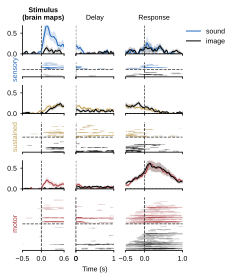

In [11]:
spec = next(s for s in CONTRASTS if s['key'] == 'sound_image')
frame = data.loc[data.contrast.eq(spec['key'])].copy()
xlims = dict(DISPLAY_WINDOWS)
original_spec = rfig3_epoch_specs[spec['source_spec']]
xlims[original_spec['phase']] = tuple(original_spec['xlim'])
floor = max(.4, float(original_spec.get('ylim', (0, .4))[1]))
ylim = rfig3_compute_shared_ylim(frame, phases=PHASES, compare_field=spec['field'], levels=spec['levels'], xlim_by_phase=xlims, ymax_floor=floor)
wave_path = IMG / ('supp_' + spec['key'] + '_waveforms_heatmaps.svg')
fig, axes = rfig3_plot_epoch_raster_traces_stack_phases(frame, phases=PHASES, compare_field=spec['field'], levels=spec['levels'], xlim_by_phase=xlims, ylim=ylim, colors=FUNCTION_COLORS, cm_per_raster_row=0.032)
fig.axes[0].get_subplotspec().get_gridspec().update(wspace=0.26)
for ax in fig.axes:
    ticklabels = ax.get_xticklabels()
    if not ticklabels or not any(label.get_visible() for label in ticklabels):
        continue
    ticks = ax.get_xticks()
    labels = [label.get_text() for label in ticklabels]
    if len(labels) != len(ticks):
        continue
    for i, tick in enumerate(ticks):
        if 1e-8 < abs(tick) < 0.08:
            labels[i] = ''
    ax.set_xticklabels(labels)
highlight_mapped_phase(fig, axes, spec)
fit_hga_canvas(fig, width_cm=13.0, max_height_cm=None)
save_svg(fig, wave_path, close=False)
plt.close(fig)
points = condition_phase_maps(frame, assignments, spec, OUT, xlims)
map_path = IMG / ('supp_' + spec['key'] + '_brain_maps.svg')
fig_maps = draw_brain_maps(points, spec, map_path)
plt.close(fig_maps)
display(SVG(filename=str(wave_path)))
display(SVG(filename=str(map_path)))


## Decision–Repeat

Shown separately: the three-phase HGA stack, then the **Delay** brain maps. Colored sites are baseline-responsive in the labeled window.

Reading labels from parcellation...


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot


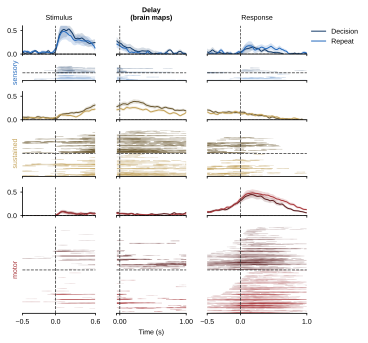

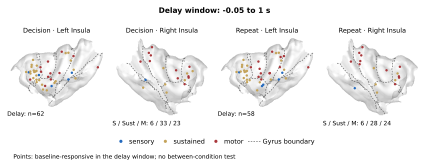

In [ ]:
spec = next(s for s in CONTRASTS if s['key'] == 'decision_repeat')
frame = data.loc[data.contrast.eq(spec['key'])].copy()
xlims = dict(DISPLAY_WINDOWS)
original_spec = rfig3_epoch_specs[spec['source_spec']]
xlims[original_spec['phase']] = tuple(original_spec['xlim'])
floor = max(.4, float(original_spec.get('ylim', (0, .4))[1]))
ylim = rfig3_compute_shared_ylim(frame, phases=PHASES, compare_field=spec['field'], levels=spec['levels'], xlim_by_phase=xlims, ymax_floor=floor)
wave_path = IMG / ('supp_' + spec['key'] + '_waveforms_heatmaps.svg')
fig, axes = rfig3_plot_epoch_raster_traces_stack_phases(frame, phases=PHASES, compare_field=spec['field'], levels=spec['levels'], xlim_by_phase=xlims, ylim=ylim, colors=FUNCTION_COLORS, cm_per_raster_row=0.032)
fig.axes[0].get_subplotspec().get_gridspec().update(wspace=0.26)
for ax in fig.axes:
    ticklabels = ax.get_xticklabels()
    if not ticklabels or not any(label.get_visible() for label in ticklabels):
        continue
    ticks = ax.get_xticks()
    labels = [label.get_text() for label in ticklabels]
    if len(labels) != len(ticks):
        continue
    for i, tick in enumerate(ticks):
        if 1e-8 < abs(tick) < 0.08:
            labels[i] = ''
    ax.set_xticklabels(labels)
highlight_mapped_phase(fig, axes, spec)
fit_hga_canvas(fig, width_cm=13.0, max_height_cm=None)
save_svg(fig, wave_path, close=False)
plt.close(fig)
points = condition_phase_maps(frame, assignments, spec, OUT, xlims)
map_path = IMG / ('supp_' + spec['key'] + '_brain_maps.svg')
fig_maps = draw_brain_maps(points, spec, map_path)
plt.close(fig_maps)
display(SVG(filename=str(wave_path)))
display(SVG(filename=str(map_path)))

## Repeat–Passive

Shown separately: the three-phase HGA stack, then the **Stimulus** brain maps. Colored sites are baseline-responsive in the labeled window.

Reading labels from parcellation...


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot


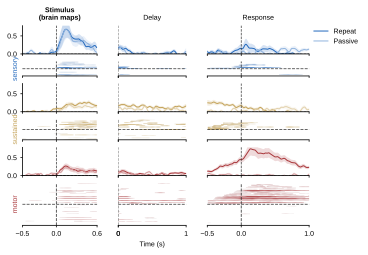

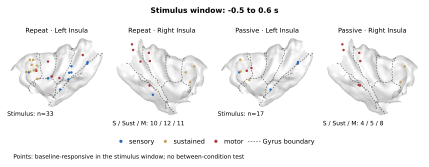

In [ ]:
spec = next(s for s in CONTRASTS if s['key'] == 'repeat_passive')
frame = data.loc[data.contrast.eq(spec['key'])].copy()
xlims = dict(DISPLAY_WINDOWS)
original_spec = rfig3_epoch_specs[spec['source_spec']]
xlims[original_spec['phase']] = tuple(original_spec['xlim'])
floor = max(.4, float(original_spec.get('ylim', (0, .4))[1]))
ylim = rfig3_compute_shared_ylim(frame, phases=PHASES, compare_field=spec['field'], levels=spec['levels'], xlim_by_phase=xlims, ymax_floor=floor)
wave_path = IMG / ('supp_' + spec['key'] + '_waveforms_heatmaps.svg')
fig, axes = rfig3_plot_epoch_raster_traces_stack_phases(frame, phases=PHASES, compare_field=spec['field'], levels=spec['levels'], xlim_by_phase=xlims, ylim=ylim, colors=FUNCTION_COLORS, cm_per_raster_row=0.032)
fig.axes[0].get_subplotspec().get_gridspec().update(wspace=0.26)
for ax in fig.axes:
    ticklabels = ax.get_xticklabels()
    if not ticklabels or not any(label.get_visible() for label in ticklabels):
        continue
    ticks = ax.get_xticks()
    labels = [label.get_text() for label in ticklabels]
    if len(labels) != len(ticks):
        continue
    for i, tick in enumerate(ticks):
        if 1e-8 < abs(tick) < 0.08:
            labels[i] = ''
    ax.set_xticklabels(labels)
highlight_mapped_phase(fig, axes, spec)
fit_hga_canvas(fig, width_cm=13.0, max_height_cm=None)
save_svg(fig, wave_path, close=False)
plt.close(fig)
points = condition_phase_maps(frame, assignments, spec, OUT, xlims)
map_path = IMG / ('supp_' + spec['key'] + '_brain_maps.svg')
fig_maps = draw_brain_maps(points, spec, map_path)
plt.close(fig_maps)
display(SVG(filename=str(wave_path)))
display(SVG(filename=str(map_path)))


In [ ]:
from src.figure3_context_draft import write_json, digest
write_json(OUT / 'completion.json', dict(contrasts=[s['key'] for s in CONTRASTS], three_phases=list(PHASES), layout='separate SVGs; HGA stack and brain maps are not assembled', brain_map_scope='condition-specific baseline masks in the labeled displayed phase window', mapped_phases={s['key']:s['map_phase'] for s in CONTRASTS}, new_condition_tests=False, assignments_sha256=digest(ROOT/'results/nmf/channel_assignments.csv')))